In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    auc
)

In [ ]:
dataset = pd.read_csv('/content/heart_attack_prediction_dataset.csv')
print("Dataset Shape:", dataset.shape)
display(dataset.head())
print(dataset.info())

Dataset Shape: (8763, 26)


,Patient ID,Age,Sex,Cholesterol,Blood Pressure,Heart Rate,Diabetes,Family History,Smoking,Obesity,...,Sedentary Hours Per Day,Income,BMI,Triglycerides,Physical Activity Days Per Week,Sleep Hours Per Day,Country,Continent,Hemisphere,Heart Attack Risk
0,BMW7812,67,Male,208,158/88,72,0,0,1,0,...,6.615001,261404,31.251233,286,0,6,Argentina,South America,Southern Hemisphere,0
1,CZE1114,21,Male,389,165/93,98,1,1,1,1,...,4.963459,285768,27.194973,235,1,7,Canada,North America,Northern Hemisphere,0
2,BNI9906,21,Female,324,174/99,72,1,0,0,0,...,9.463426,235282,28.176571,587,4,4,France,Europe,Northern Hemisphere,0
3,JLN3497,84,Male,383,163/100,73,1,1,1,0,...,7.648981,125640,36.464704,378,3,4,Canada,North America,Northern Hemisphere,0
4,GFO8847,66,Male,318,91/88,93,1,1,1,1,...,1.514821,160555,21.809144,231,1,5,Thailand,Asia,Northern Hemisphere,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8763 entries, 0 to 8762
Data columns (total 26 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   Patient ID                       8763 non-null   object 
 1   Age                              8763 non-null   int64  
 2   Sex                              8763 non-null   object 
 3   Cholesterol                      8763 non-null   int64  
 4   Blood Pressure                   8763 non-null   object 
 5   Heart Rate                       8763 non-null   int64  
 6   Diabetes                         8763 non-null   int64  
 7   Family History                   8763 non-null   int64  
 8   Smoking                          8763 non-null   int64  
 9   Obesity                          8763 non-null   int64  
 10  Alcohol Consumption              8763 non-null   int64  
 11  Exercise Hours Per Week          8763 non-null   float64
 12  Diet                

In [ ]:
if 'Blood Pressure' in dataset.columns:
    dataset[['Systolic_BP', 'Diastolic_BP']] = dataset['Blood Pressure'].str.split('/', expand=True).astype(float)
    dataset = dataset.drop(columns=['Blood Pressure'])

to_drop = [col for col in ['Patient ID', 'Country'] if col in dataset.columns]
if to_drop:
    dataset = dataset.drop(columns=to_drop)

categorical_cols = [col for col in ['Sex', 'Diet', 'Continent', 'Hemisphere'] if col in dataset.columns]
if categorical_cols:
    dataset = pd.get_dummies(dataset, columns=categorical_cols, drop_first=True)

print("Processed dataset columns:", dataset.columns)
print("New shape:", dataset.shape)
display(dataset.head())

Processed dataset columns: Index(['Age', 'Cholesterol', 'Heart Rate', 'Diabetes', 'Family History',
       'Smoking', 'Obesity', 'Alcohol Consumption', 'Exercise Hours Per Week',
       'Previous Heart Problems', 'Medication Use', 'Stress Level',
       'Sedentary Hours Per Day', 'Income', 'BMI', 'Triglycerides',
       'Physical Activity Days Per Week', 'Sleep Hours Per Day',
       'Heart Attack Risk', 'Systolic_BP', 'Diastolic_BP', 'Sex_Male',
       'Diet_Healthy', 'Diet_Unhealthy', 'Continent_Asia',
       'Continent_Australia', 'Continent_Europe', 'Continent_North America',
       'Continent_South America', 'Hemisphere_Southern Hemisphere'],
      dtype='object')
New shape: (8763, 30)


,Age,Cholesterol,Heart Rate,Diabetes,Family History,Smoking,Obesity,Alcohol Consumption,Exercise Hours Per Week,Previous Heart Problems,...,Diastolic_BP,Sex_Male,Diet_Healthy,Diet_Unhealthy,Continent_Asia,Continent_Australia,Continent_Europe,Continent_North America,Continent_South America,Hemisphere_Southern Hemisphere
0,67,208,72,0,0,1,0,0,4.168189,0,...,88.0,True,False,False,False,False,False,False,True,True
1,21,389,98,1,1,1,1,1,1.813242,1,...,93.0,True,False,True,False,False,False,True,False,False
2,21,324,72,1,0,0,0,0,2.078353,1,...,99.0,False,True,False,False,False,True,False,False,False
3,84,383,73,1,1,1,0,1,9.828130,1,...,100.0,True,False,False,False,False,False,True,False,False
4,66,318,93,1,1,1,1,0,5.804299,1,...,88.0,True,False,True,True,False,False,False,False,False


In [ ]:
X = dataset.drop('Heart Attack Risk', axis=1)
Y = dataset['Heart Attack Risk']

X_train, X_test, Y_train, Y_test = train_test_split(
    X,
    Y,
    test_size=0.20,
    random_state=0,
    stratify=Y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (7010, 29)
Testing shape: (1753, 29)


In [ ]:
model = LogisticRegression(random_state=0, max_iter=1000)
model.fit(X_train, Y_train)

Y_pred = model.predict(X_test)
Y_prob = model.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(Y_test, Y_pred)
precision = precision_score(Y_test, Y_pred, zero_division=0)
recall = recall_score(Y_test, Y_pred, zero_division=0)
f1 = f1_score(Y_test, Y_pred, zero_division=0)

print("Logistic Regression Accuracy  :", accuracy)
print("Logistic Regression Precision :", precision)
print("Logistic Regression Recall    :", recall)
print("Logistic Regression F1 Score  :", f1)

Logistic Regression Accuracy  : 0.6417569880205363
Logistic Regression Precision : 0.0
Logistic Regression Recall    : 0.0
Logistic Regression F1 Score  : 0.0


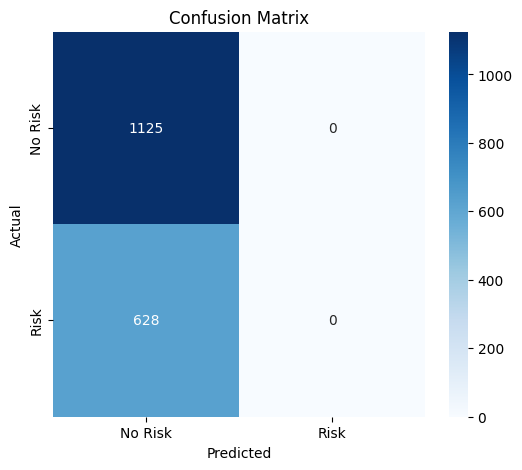

In [ ]:
cm = confusion_matrix(Y_test, Y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Risk', 'Risk'],
    yticklabels=['No Risk', 'Risk']
)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

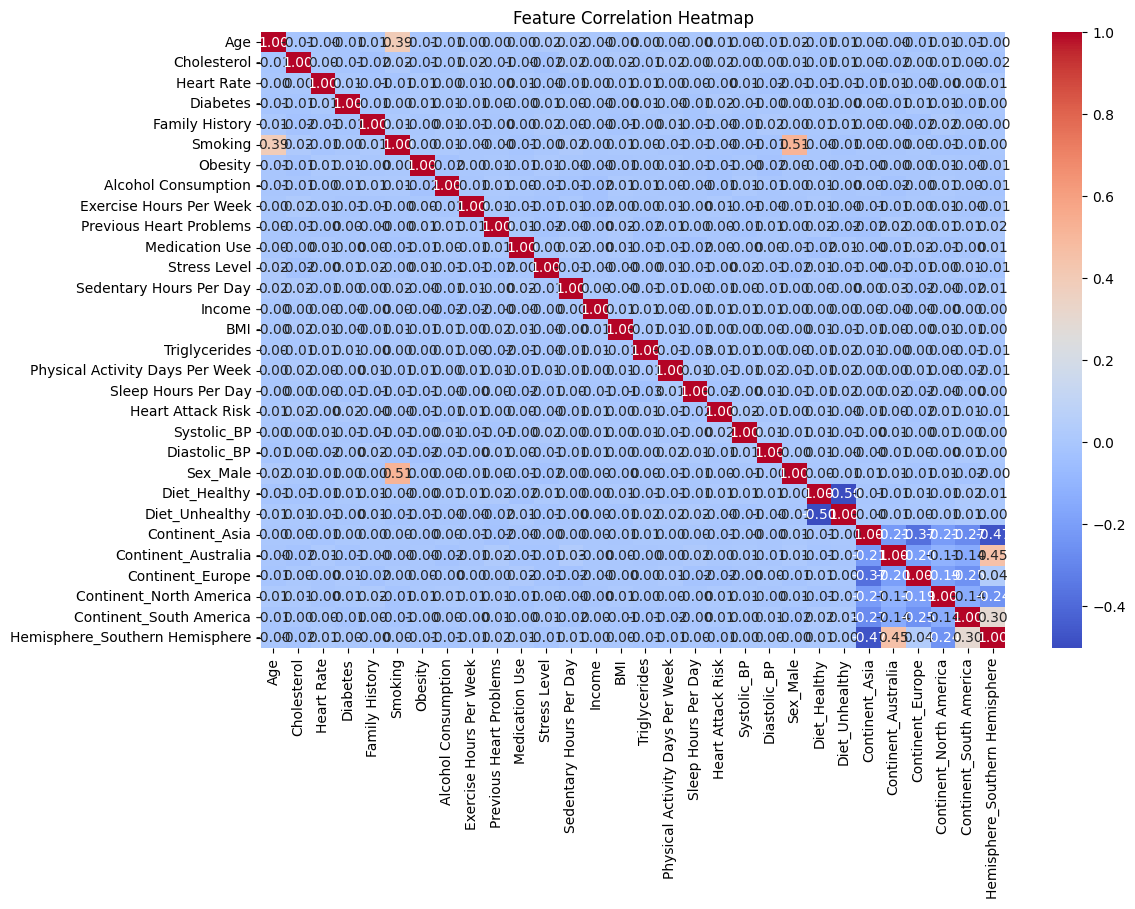

In [ ]:
plt.figure(figsize=(12, 8))
sns.heatmap(
    dataset.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)
plt.title("Feature Correlation Heatmap")
plt.show()

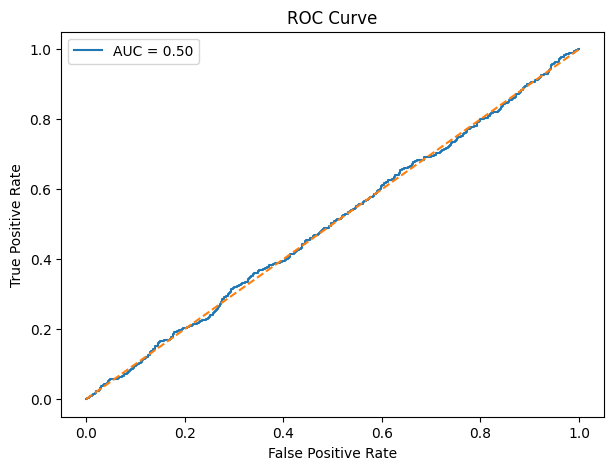

In [ ]:
fpr, tpr, thresholds = roc_curve(Y_test, Y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f'AUC = {roc_auc:.2f}')
plt.plot([0, 1], [0, 1], '--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(random_state=0, max_iter=1000),
    "Random Forest": RandomForestClassifier(random_state=0),
    "Gradient Boosting": GradientBoostingClassifier(random_state=0)
}

results = []
for name, clf in models.items():
    clf.fit(X_train, Y_train)
    preds = clf.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(Y_test, preds),
        "Precision": precision_score(Y_test, preds, zero_division=0),
        "Recall": recall_score(Y_test, preds, zero_division=0),
        "F1 Score": f1_score(Y_test, preds, zero_division=0)
    })

df_compare = pd.DataFrame(results)
display(df_compare)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.641757,0.000000,0.000000,0.000000
1,Random Forest,0.637193,0.400000,0.025478,0.047904
2,Gradient Boosting,0.640616,0.464286,0.020701,0.039634


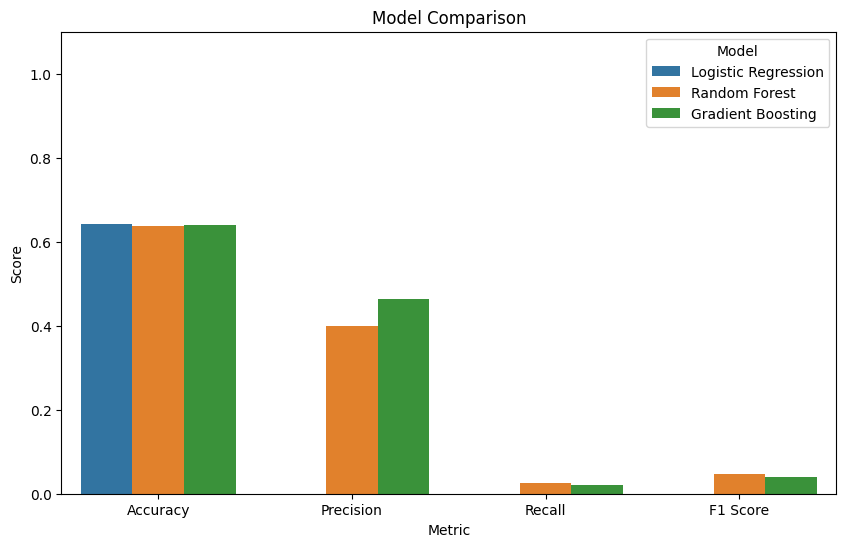

In [ ]:
df_melted = df_compare.melt(id_vars="Model", var_name="Metric", value_name="Value")
plt.figure(figsize=(10, 6))
sns.barplot(data=df_melted, x="Metric", y="Value", hue="Model")
plt.title("Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.1)
plt.show()

In [ ]:
best_model_info = df_compare.sort_values(by=["F1 Score", "Accuracy"], ascending=False).iloc[0]
print(f"Best Model: {best_model_info['Model']}")
print(best_model_info)

Best Model: Random Forest
Model        Random Forest
Accuracy          0.637193
Precision              0.4
Recall            0.025478
F1 Score          0.047904
Name: 1, dtype: object


In [ ]:
print("All processes completed successfully.")

All processes completed successfully.


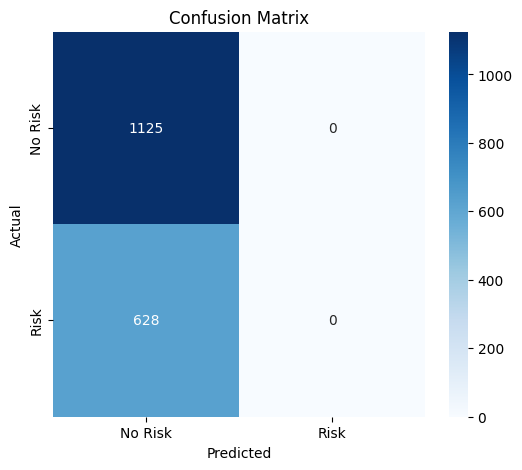

In [ ]:
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['No Risk', 'Risk'],
    yticklabels=['No Risk', 'Risk']
)
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()